# Tahap 1

In [ ]:
#@title 1 - Import library
import os
import json
import yaml
import zipfile
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = False

sns.set_theme(style="whitegrid")

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [ ]:
#@title 2 - Ekstrak dataset
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/oil_palm_dataset.zip")
EXTRACT_PATH = Path("/content/oil_palm_dataset")

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"File tidak ditemukan di: {ZIP_PATH}")

EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset berhasil diekstrak.")
print("Lokasi:", EXTRACT_PATH)

KeyboardInterrupt: 

In [ ]:
#@title 3 - Identifikasi gambar dan file CSV
ROOT = EXTRACT_PATH

SPLITS = ["train", "valid", "test"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

split_dirs = {
    split: next(
        (p for p in ROOT.rglob(split) if p.is_dir()),
        None
    )
    for split in SPLITS
}

image_files = []
csv_files = {}

for split, folder in split_dirs.items():

    if folder is None:
        print(f"Folder {split} tidak ditemukan.")
        continue

    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    csvs = list(folder.glob("*.csv"))

    image_files.extend(images)

    if csvs:
        csv_files[split] = csvs[0]

    print(f"\n{split.upper()}")
    print("Jumlah gambar:", len(images))
    print("CSV:", csvs[0].name if csvs else "Tidak ditemukan")

print("\nTOTAL GAMBAR:", len(image_files))


TRAIN
Jumlah gambar: 5610
CSV: _classes.csv

VALID
Jumlah gambar: 535
CSV: _classes.csv

TEST
Jumlah gambar: 267
CSV: _classes.csv

TOTAL GAMBAR: 6412


# Tahap 2

In [ ]:
#@title 4 - Menghitung ukuran dan format dataset
total_size = sum(p.stat().st_size for p in image_files)

extension_counts = Counter(
    p.suffix.lower() for p in image_files
)

dataset_info = {
    "Total gambar": len(image_files),
    "Ukuran dataset (MB)": round(total_size / (1024**2), 2),
    "Jumlah format gambar": len(extension_counts),
    "Format gambar": ", ".join(extension_counts.keys())
}

display(pd.DataFrame(
    dataset_info.items(),
    columns=["Informasi", "Nilai"]
))

print("\nDistribusi format file:")
display(pd.DataFrame(
    extension_counts.items(),
    columns=["Format", "Jumlah"]
))

,Informasi,Nilai
0,Total gambar,6412
1,Ukuran dataset (MB),695.08
2,Jumlah format gambar,1
3,Format gambar,.jpg



Distribusi format file:


,Format,Jumlah
0,.jpg,6412


In [ ]:
#@title 5 - Inventarisasi metadata setiap gambar
records = []

for path in image_files:
    try:
        with Image.open(path) as img:
            width, height = img.size

            records.append({
                "filename": path.name,
                "path": str(path),
                "split": next(
                    (part.lower() for part in path.parts
                     if part.lower() in SPLITS),
                    "unknown"
                ),
                "extension": path.suffix.lower(),
                "width": width,
                "height": height,
                "channels": len(img.getbands()),
                "color_mode": img.mode,
                "format": img.format,
                "aspect_ratio": round(width / height, 3),
                "file_size_kb": round(
                    path.stat().st_size / 1024, 2
                ),
                "is_valid": True
            })

    except Exception as e:
        records.append({
            "filename": path.name,
            "path": str(path),
            "split": "unknown",
            "extension": path.suffix.lower(),
            "width": None,
            "height": None,
            "channels": None,
            "color_mode": None,
            "format": None,
            "aspect_ratio": None,
            "file_size_kb": round(
                path.stat().st_size / 1024, 2
            ),
            "is_valid": False
        })

df = pd.DataFrame(records)

print("Inventarisasi selesai.")
print("Total gambar:", len(df))
print("Gambar valid:", df["is_valid"].sum())
print("Gambar rusak/tidak terbaca:", (~df["is_valid"]).sum())

display(df.head())

Inventarisasi selesai.
Total gambar: 6412
Gambar valid: 6412
Gambar rusak/tidak terbaca: 0


,filename,path,split,extension,width,height,channels,color_mode,format,aspect_ratio,file_size_kb,is_valid
0,unripe-221-_jpg.rf.7c58d1ed7ff77dcbe0aaf3465ec...,/content/oil_palm_dataset/train/unripe-221-_jp...,train,.jpg,640,640,3,RGB,JPEG,1.0,80.59,True
1,underripe-274-_jpg.rf.ba952c48a190242b7c2557a9...,/content/oil_palm_dataset/train/underripe-274-...,train,.jpg,640,640,3,RGB,JPEG,1.0,115.51,True
2,ripe-502-_jpg.rf.a489f271ee9aa1b3ee69063b7456c...,/content/oil_palm_dataset/train/ripe-502-_jpg....,train,.jpg,640,640,3,RGB,JPEG,1.0,166.54,True
3,underripe-96-_png.rf.967ce23a456e5ec6746178945...,/content/oil_palm_dataset/train/underripe-96-_...,train,.jpg,640,640,3,RGB,JPEG,1.0,87.48,True
4,ripe-670-_JPG.rf.14260bc078daeca025a4ea6972639...,/content/oil_palm_dataset/train/ripe-670-_JPG....,train,.jpg,640,640,3,RGB,JPEG,1.0,107.46,True


In [ ]:
#@title 6 - Statistik resolusi dan dimensi gambar
valid_df = df[df["is_valid"]].copy()

print("Statistik dimensi gambar:")
display(valid_df[["width", "height", "channels"]].describe())

print("\nDistribusi resolusi:")
display(
    valid_df.groupby(["width", "height"])
    .size()
    .reset_index(name="jumlah")
    .sort_values("jumlah", ascending=False)
    .head(20)
)

print("\nDistribusi mode warna:")
display(valid_df["color_mode"].value_counts().to_frame("jumlah"))

Statistik dimensi gambar:


,width,height,channels
count,6412.0,6412.0,6412.0
mean,640.0,640.0,3.0
std,0.0,0.0,0.0
min,640.0,640.0,3.0
25%,640.0,640.0,3.0
50%,640.0,640.0,3.0
75%,640.0,640.0,3.0
max,640.0,640.0,3.0



Distribusi resolusi:


,width,height,jumlah
0,640,640,6412



Distribusi mode warna:


,jumlah
color_mode,
RGB,6412


# Tahap 3 – Identifikasi kelas dan distribusi data

In [ ]:
#@title Duplicate

def calculate_hash(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            sha.update(chunk)

    return sha.hexdigest()


hash_records = []

for path in image_files:
    hash_records.append({
        "filename": path.name,
        "path": str(path),
        "split": next(
            (part.lower() for part in path.parts
             if part.lower() in SPLITS),
            "unknown"
        ),
        "hash": calculate_hash(path)
    })

hash_df = pd.DataFrame(hash_records)

# Kelompok gambar dengan hash identik
duplicates = hash_df[
    hash_df.duplicated(subset="hash", keep=False)
].sort_values("hash")

# Duplikasi lintas partisi
cross_split = (
    duplicates.groupby("hash")["split"]
    .nunique()
)

cross_split_hashes = cross_split[cross_split > 1].index

cross_split_duplicates = duplicates[
    duplicates["hash"].isin(cross_split_hashes)
]

print("Total gambar:", len(hash_df))
print("Hash unik:", hash_df["hash"].nunique())
print("Jumlah gambar duplikat:",
      len(hash_df) - hash_df["hash"].nunique())
print("Kelompok gambar duplikat:", len(cross_split))
print("Kelompok duplikat lintas split:",
      len(cross_split_hashes))

display(duplicates.head(30))

Total gambar: 6412
Hash unik: 6412
Jumlah gambar duplikat: 0
Kelompok gambar duplikat: 0
Kelompok duplikat lintas split: 0


,filename,path,split,hash


In [ ]:
#@title Outliers
features = [
    "width",
    "height",
    "aspect_ratio",
    "file_size_kb"
]

outlier_results = []

for feature in features:

    Q1 = valid_df[feature].quantile(0.25)
    Q3 = valid_df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (
        (valid_df[feature] < lower) |
        (valid_df[feature] > upper)
    )

    outlier_results.append({
        "Fitur": feature,
        "Q1": Q1,
        "Q3": Q3,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Jumlah Outlier": int(mask.sum()),
        "Persentase (%)": round(
            mask.mean() * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Fitur,Q1,Q3,Lower Bound,Upper Bound,Jumlah Outlier,Persentase (%)
0,width,640.0000,640.0000,640.00,640.00,0,0.00
1,height,640.0000,640.0000,640.00,640.00,0,0.00
2,aspect_ratio,1.0000,1.0000,1.00,1.00,0,0.00
3,file_size_kb,92.9775,124.9425,45.03,172.89,114,1.78


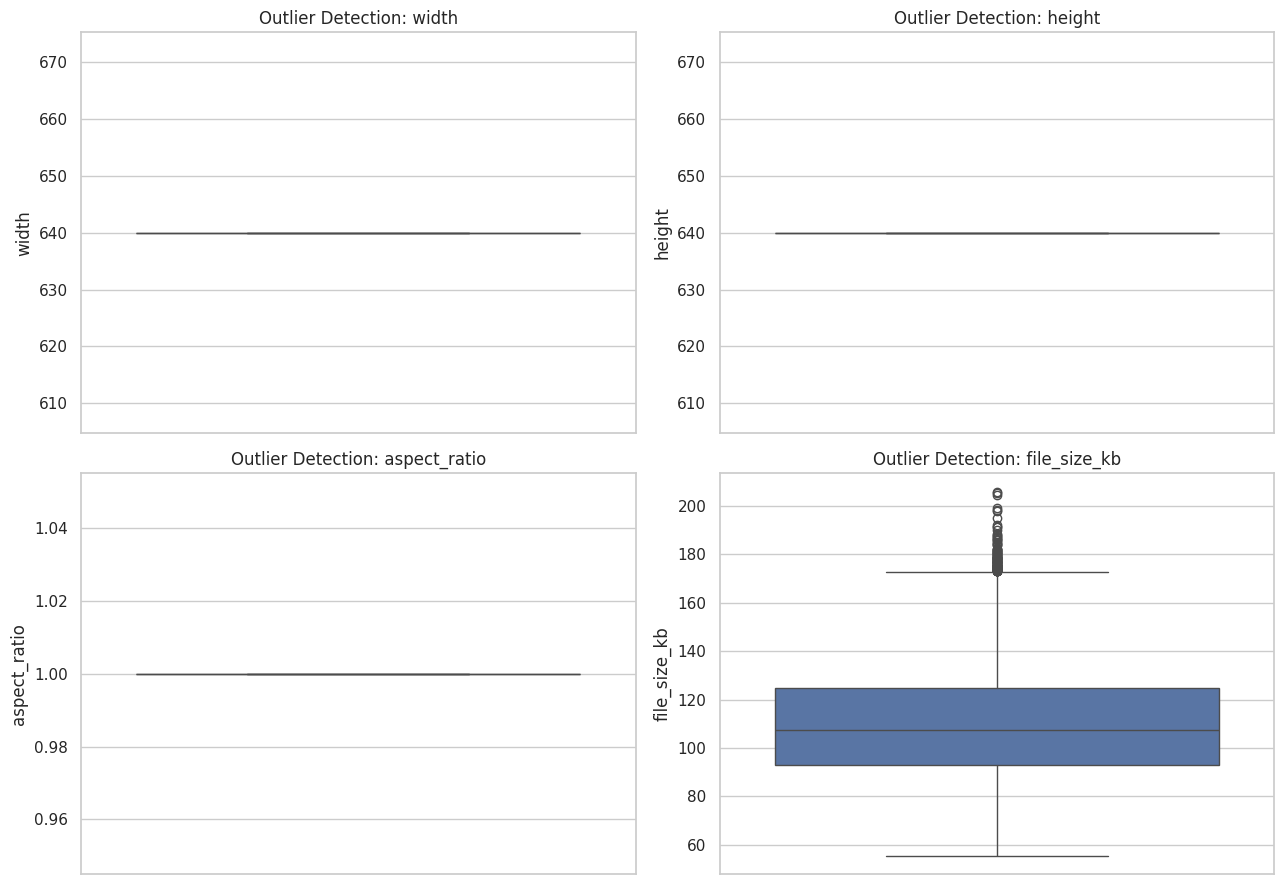

In [ ]:
#@title Outliers #2
features = [
    "width",
    "height",
    "aspect_ratio",
    "file_size_kb"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for feature, ax in zip(features, axes.flatten()):

    sns.boxplot(
        data=valid_df,
        y=feature,
        ax=ax
    )

    ax.set_title(f"Outlier Detection: {feature}")

plt.tight_layout()
plt.show()

Total gambar terindikasi outlier: 114


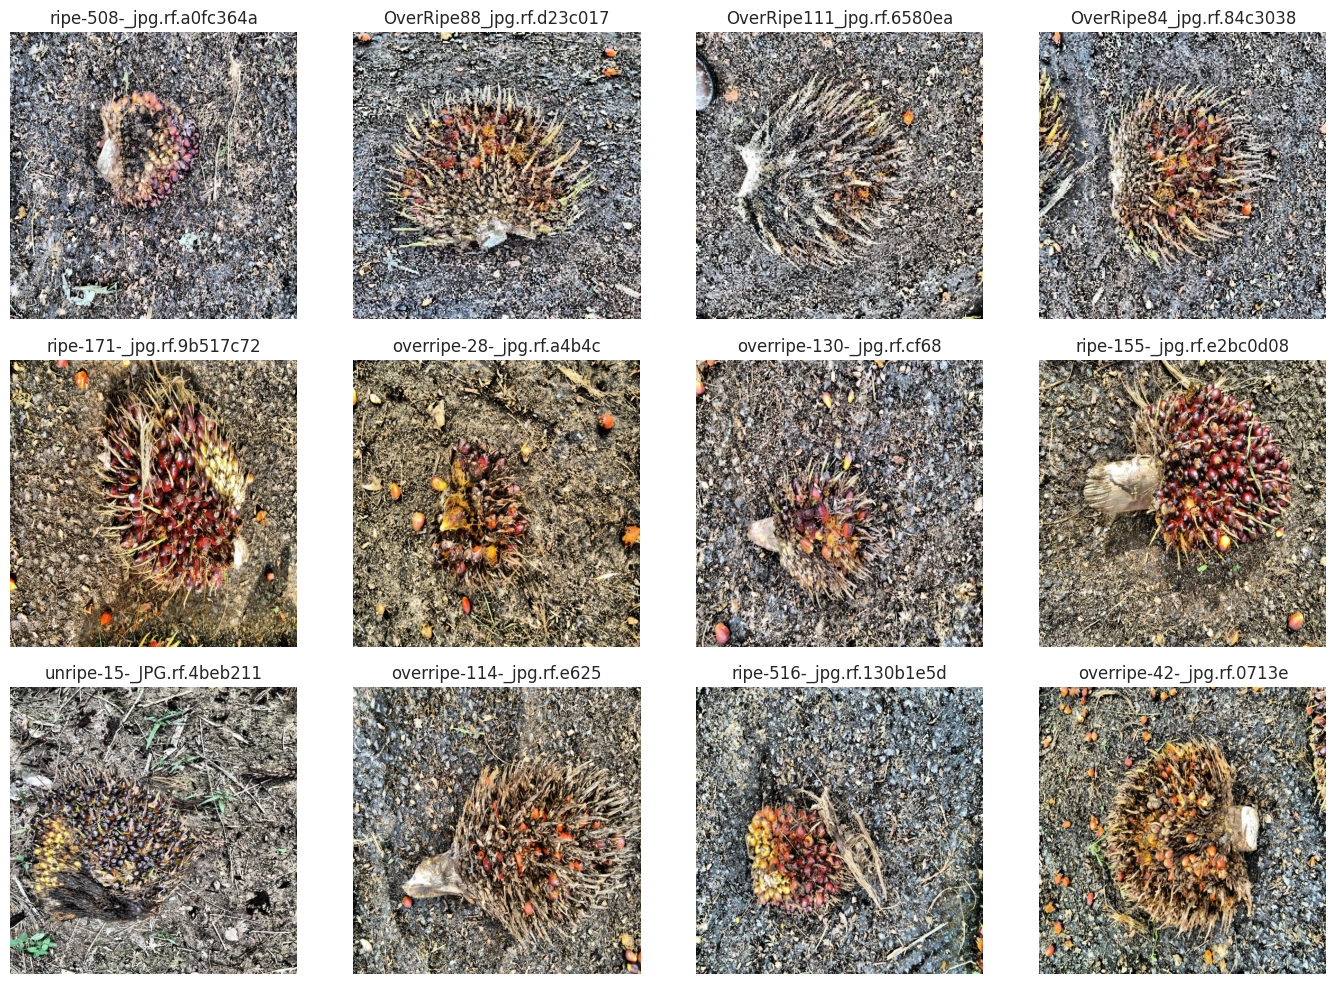

In [ ]:
#@title Outliers #3
outlier_images = set()

for feature in features:

    Q1 = valid_df[feature].quantile(0.25)
    Q3 = valid_df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    selected = valid_df[
        (valid_df[feature] < lower) |
        (valid_df[feature] > upper)
    ]

    outlier_images.update(selected["path"])

outlier_images = list(outlier_images)

print("Total gambar terindikasi outlier:",
      len(outlier_images))

fig, axes = plt.subplots(
    min(3, len(outlier_images)),
    4,
    figsize=(14, 10)
)

axes = np.array(axes).reshape(-1, 4)

for i, path in enumerate(outlier_images[:12]):

    img = Image.open(path).convert("RGB")

    axes[i // 4, i % 4].imshow(img)
    axes[i // 4, i % 4].set_title(
        Path(path).name[:25]
    )
    axes[i // 4, i % 4].axis("off")

for i in range(min(12, len(outlier_images)), 12):
    axes[i // 4, i % 4].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#@title 7 - Membaca label dari CSV
import pandas as pd
from pathlib import Path

CLASS_COLUMNS = [
    "overripe",
    "ripe",
    "underripe",
    "unripe"
]

all_data = []

for split, csv_path in csv_files.items():

    temp = pd.read_csv(csv_path)

    print(f"\n{split.upper()} CSV")
    print("Kolom:", temp.columns.tolist())
    print("Jumlah baris:", len(temp))

    # Pastikan kolom target tersedia
    missing_columns = [
        col for col in CLASS_COLUMNS
        if col not in temp.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Kolom kelas tidak ditemukan: {missing_columns}"
        )

    temp["split"] = split

    # Konversi one-hot menjadi satu label kelas
    temp["label"] = temp[CLASS_COLUMNS].idxmax(axis=1)

    # Memeriksa apakah setiap baris memiliki tepat satu label aktif
    temp["active_labels"] = temp[CLASS_COLUMNS].sum(axis=1)

    all_data.append(temp)

df_labels = pd.concat(all_data, ignore_index=True)

print("\nTotal data berlabel:", len(df_labels))

display(df_labels.head(10))


TRAIN CSV
Kolom: ['filename', 'overripe', 'ripe', 'underripe', 'unripe']
Jumlah baris: 5610

VALID CSV
Kolom: ['filename', 'overripe', 'ripe', 'underripe', 'unripe']
Jumlah baris: 535

TEST CSV
Kolom: ['filename', 'overripe', 'ripe', 'underripe', 'unripe']
Jumlah baris: 267

Total data berlabel: 6412


,filename,overripe,ripe,underripe,unripe,split,label,active_labels
0,overripe-331-_jpg.rf.c1763e711e9ef04733e50d111...,1,0,0,0,train,overripe,1
1,ripe-142-_jpg.rf.08f25705cee08800d054de12cc10b...,0,1,0,0,train,ripe,1
2,ripe-320-_jpg.rf.128360b737a545d72dcf2756f5415...,0,1,0,0,train,ripe,1
3,underripe-166-_png.rf.11d7ca27b9d442bf1a518e05...,0,0,1,0,train,underripe,1
4,underripe-650-_jpg.rf.f0094e57fc4e11bf3b8822ac...,0,0,0,0,train,overripe,0
5,ripe-33-_jpg.rf.baa6b566a7a95572efd4b721590533...,0,1,0,0,train,ripe,1
6,ripe-158-_jpg.rf.75ca15618215573e1f800c508ba25...,0,1,0,0,train,ripe,1
7,unripe-405-_jpg.rf.5b35befbc0d6a1c16ed4f94364f...,0,0,0,1,train,unripe,1
8,underripe-617-_jpg.rf.6c2749358cfb5205f51e54e8...,0,0,1,0,train,underripe,1
9,overripe-367-_jpg.rf.ff0b7f3e97a47d03a576fc0d4...,1,0,0,0,train,overripe,1


In [ ]:
#@title 8 - Validasi label dan mencocokkan gambar
image_lookup = {
    p.name: p for p in image_files
}

df_labels["image_path"] = (
    df_labels["filename"]
    .map(image_lookup)
)

df_labels["image_exists"] = (
    df_labels["image_path"].notna()
)

# Pemeriksaan validitas one-hot
valid_one_hot = (
    df_labels["active_labels"] == 1
)

print("Total baris CSV:", len(df_labels))

print(
    "Label one-hot valid:",
    valid_one_hot.sum()
)

print(
    "Label tidak valid:",
    (~valid_one_hot).sum()
)

print(
    "Gambar ditemukan:",
    df_labels["image_exists"].sum()
)

print(
    "Gambar tidak ditemukan:",
    (~df_labels["image_exists"]).sum()
)

# Periksa gambar tanpa pasangan di CSV
csv_filenames = set(df_labels["filename"])
image_filenames = set(image_lookup.keys())

unlabeled_images = image_filenames - csv_filenames

print(
    "Gambar tanpa label CSV:",
    len(unlabeled_images)
)

display(
    df_labels[
        (~valid_one_hot) | (~df_labels["image_exists"])
    ].head(20)
)

Total baris CSV: 6412
Label one-hot valid: 5790
Label tidak valid: 622
Gambar ditemukan: 6412
Gambar tidak ditemukan: 0
Gambar tanpa label CSV: 0


,filename,overripe,ripe,underripe,unripe,split,label,active_labels,image_path,image_exists
4,underripe-650-_jpg.rf.f0094e57fc4e11bf3b8822ac...,0,0,0,0,train,overripe,0,/content/oil_palm_dataset/train/underripe-650-...,True
17,underripe-299-_jpg.rf.7f5a2476aaa107ac6978bca0...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/underripe-299-...,True
30,ripe-706-_jpg.rf.fa951c711c3f7f8fad122b4414dd3...,0,1,0,1,train,ripe,2,/content/oil_palm_dataset/train/ripe-706-_jpg....,True
56,ripe-29-_jpg.rf.b3524acba5ddc6b139d27cf93790dd...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/ripe-29-_jpg.r...,True
65,unripe-71-_JPG.rf.68118adb70dce8c13da609a8078b...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/unripe-71-_JPG...,True
75,unripe-71-_JPG.rf.a9f3d8217f4689113be0a3255990...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/unripe-71-_JPG...,True
80,underripe-110-_png.rf.33c5b83a9f361a70e69686b0...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/underripe-110-...,True
103,underripe-152-_png.rf.1273ec709168aa8091008888...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/underripe-152-...,True
105,underripe-190-_JPG.rf.881f5456ea5f925810060016...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/underripe-190-...,True
127,underripe-721-_jpg.rf.0a6bad0ad8e518851ecdde17...,0,0,1,1,train,underripe,2,/content/oil_palm_dataset/train/underripe-721-...,True


In [ ]:
#@title 9 - Distribusi kelas berdasarkan partisi
class_distribution = (
    df_labels.groupby(["split", "label"])
    .size()
    .reset_index(name="jumlah_gambar")
)

display(
    class_distribution.pivot(
        index="label",
        columns="split",
        values="jumlah_gambar"
    ).fillna(0).astype(int)
)

# Distribusi keseluruhan
total_distribution = (
    df_labels["label"]
    .value_counts()
)

distribution_df = pd.DataFrame({
    "kelas": total_distribution.index,
    "jumlah_gambar": total_distribution.values
})

distribution_df["persentase"] = (
    distribution_df["jumlah_gambar"]
    / distribution_df["jumlah_gambar"].sum() * 100
).round(2)

display(distribution_df)

imbalance_ratio = (
    total_distribution.max() /
    total_distribution.min()
)

print("Imbalance Ratio:", round(imbalance_ratio, 2))

split,test,train,valid
label,,,
overripe,85,1587,159
ripe,66,1476,134
underripe,68,1533,150
unripe,48,1014,92


,kelas,jumlah_gambar,persentase
0,overripe,1831,28.56
1,underripe,1751,27.31
2,ripe,1676,26.14
3,unripe,1154,18.00


Imbalance Ratio: 1.59


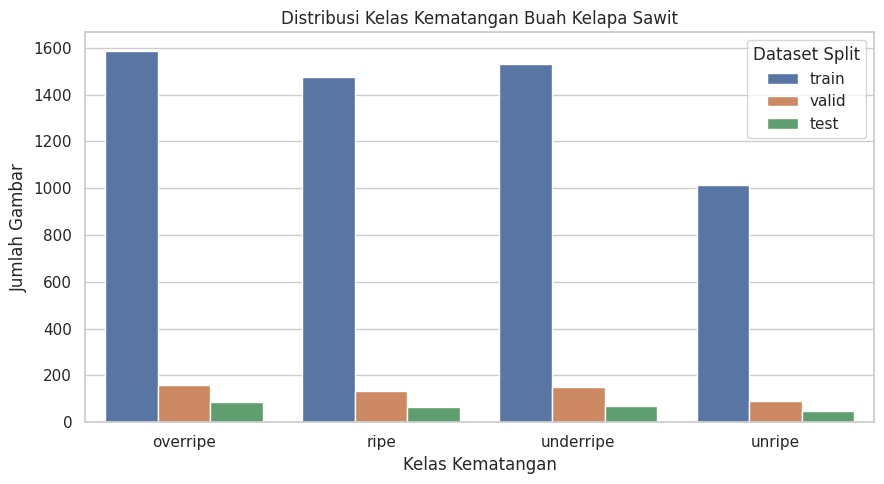

In [ ]:
#@title 10 - Visualisasi distribusi kelas
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_labels,
    x="label",
    hue="split",
    order=CLASS_COLUMNS
)

plt.title("Distribusi Kelas Kematangan Buah Kelapa Sawit")
plt.xlabel("Kelas Kematangan")
plt.ylabel("Jumlah Gambar")
plt.legend(title="Dataset Split")

plt.tight_layout()
plt.show()

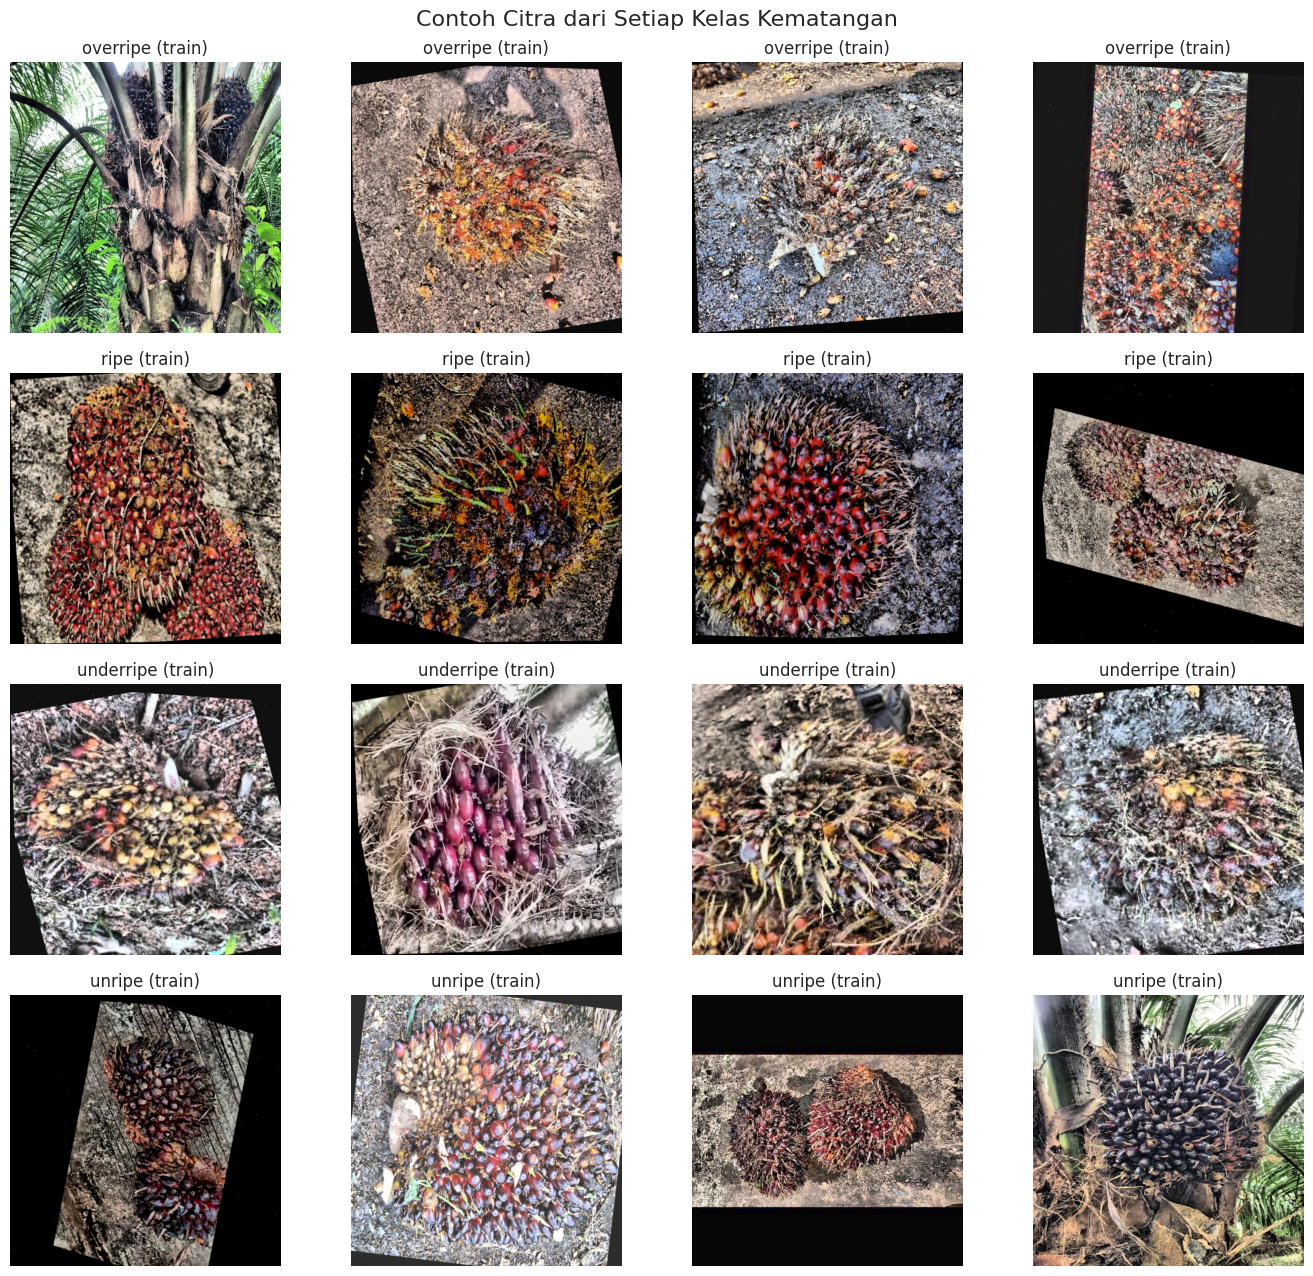

In [ ]:
#@title 11 - Visualisasi sampel gambar
fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 13)
)

for row, label in enumerate(CLASS_COLUMNS):

    samples = df_labels[
        (df_labels["label"] == label) &
        (df_labels["image_exists"])
    ].sample(
        min(4, len(df_labels[
            (df_labels["label"] == label) &
            (df_labels["image_exists"])
        ])),
        random_state=42
    )

    for col, (_, sample) in enumerate(samples.iterrows()):

        img = Image.open(sample["image_path"]).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(
            f"{label} ({sample['split']})"
        )
        axes[row, col].axis("off")

    for col in range(len(samples), 4):
        axes[row, col].axis("off")

plt.suptitle(
    "Contoh Citra dari Setiap Kelas Kematangan",
    fontsize=16
)

plt.tight_layout()
plt.show()

#Tahap 3 - Perbaikan

In [ ]:
#@title Validasi One-Hot Encoding
CLASS_COLUMNS = [
    "overripe",
    "ripe",
    "underripe",
    "unripe"
]

# Pastikan kolom kelas berupa numerik
df_labels[CLASS_COLUMNS] = df_labels[
    CLASS_COLUMNS
].apply(pd.to_numeric, errors="coerce")

# Hitung jumlah label aktif
df_labels["active_labels"] = (
    df_labels[CLASS_COLUMNS].sum(axis=1)
)

# Periksa apakah semua nilai hanya 0 atau 1
binary_valid = df_labels[CLASS_COLUMNS].isin([0, 1]).all(axis=1)

# Klasifikasi kondisi label
df_labels["label_status"] = np.select(
    [
        ~binary_valid,
        df_labels["active_labels"] == 0,
        df_labels["active_labels"] > 1,
        df_labels["active_labels"] == 1
    ],
    [
        "invalid_value",
        "all_zero",
        "multi_hot",
        "valid"
    ],
    default="unknown"
)

# Hanya ambil data dengan label valid
df_valid = df_labels[
    df_labels["label_status"] == "valid"
].copy()

# Ambil kelas setelah validasi
df_valid["label"] = (
    df_valid[CLASS_COLUMNS]
    .idxmax(axis=1)
)

print("TOTAL DATA:", len(df_labels))
print("LABEL VALID:", len(df_valid))
print("LABEL TIDAK VALID:", len(df_labels) - len(df_valid))

print("\nStatus Label:")
display(
    df_labels["label_status"]
    .value_counts()
    .to_frame("jumlah")
)

TOTAL DATA: 6412
LABEL VALID: 5790
LABEL TIDAK VALID: 622

Status Label:


,jumlah
label_status,
valid,5790
multi_hot,480
all_zero,142


In [ ]:
#@title Analisis penyebab label tidak valid
invalid_df = df_labels[
    df_labels["label_status"] != "valid"
].copy()

print("Distribusi masalah label berdasarkan partisi:")

display(
    pd.crosstab(
        invalid_df["split"],
        invalid_df["label_status"]
    )
)

print("\nPola kombinasi label yang tidak valid:")

invalid_df["label_pattern"] = (
    invalid_df[CLASS_COLUMNS]
    .fillna(-1)
    .astype(str)
    .agg("".join, axis=1)
)

display(
    invalid_df["label_pattern"]
    .value_counts()
    .to_frame("jumlah")
)

print("\nContoh data bermasalah:")

display(
    invalid_df[
        ["filename", "split"] +
        CLASS_COLUMNS +
        ["label_status"]
    ].head(30)
)

Distribusi masalah label berdasarkan partisi:


label_status,all_zero,multi_hot
split,,
test,5,20
train,120,416
valid,17,44



Pola kombinasi label yang tidak valid:


,jumlah
label_pattern,
0011,341
0000,142
1100,58
0101,38
1001,22
0110,12
0111,6
1010,3



Contoh data bermasalah:


,filename,split,overripe,ripe,underripe,unripe,label_status
4,underripe-650-_jpg.rf.f0094e57fc4e11bf3b8822ac...,train,0,0,0,0,all_zero
17,underripe-299-_jpg.rf.7f5a2476aaa107ac6978bca0...,train,0,0,1,1,multi_hot
30,ripe-706-_jpg.rf.fa951c711c3f7f8fad122b4414dd3...,train,0,1,0,1,multi_hot
56,ripe-29-_jpg.rf.b3524acba5ddc6b139d27cf93790dd...,train,0,0,1,1,multi_hot
65,unripe-71-_JPG.rf.68118adb70dce8c13da609a8078b...,train,0,0,1,1,multi_hot
75,unripe-71-_JPG.rf.a9f3d8217f4689113be0a3255990...,train,0,0,1,1,multi_hot
80,underripe-110-_png.rf.33c5b83a9f361a70e69686b0...,train,0,0,1,1,multi_hot
103,underripe-152-_png.rf.1273ec709168aa8091008888...,train,0,0,1,1,multi_hot
105,underripe-190-_JPG.rf.881f5456ea5f925810060016...,train,0,0,1,1,multi_hot
127,underripe-721-_jpg.rf.0a6bad0ad8e518851ecdde17...,train,0,0,1,1,multi_hot


In [ ]:
#@title Distribusi kelas yang benar
class_distribution = (
    df_valid.groupby(["split", "label"])
    .size()
    .reset_index(name="jumlah_gambar")
)

distribution_table = class_distribution.pivot(
    index="label",
    columns="split",
    values="jumlah_gambar"
).fillna(0).astype(int)

display(distribution_table)

# Distribusi keseluruhan
total_distribution = (
    df_valid["label"].value_counts()
    .reindex(CLASS_COLUMNS, fill_value=0)
)

distribution_df = pd.DataFrame({
    "kelas": total_distribution.index,
    "jumlah_gambar": total_distribution.values
})

distribution_df["persentase"] = (
    distribution_df["jumlah_gambar"]
    / distribution_df["jumlah_gambar"].sum() * 100
).round(2)

display(distribution_df)

imbalance_ratio = (
    total_distribution.max() /
    total_distribution.min()
)

print("Jumlah data valid:", len(df_valid))
print("Imbalance Ratio:", round(imbalance_ratio, 2))

split,test,train,valid
label,,,
overripe,78,1392,136
ripe,61,1431,128
underripe,55,1237,118
unripe,48,1014,92


,kelas,jumlah_gambar,persentase
0,overripe,1606,27.74
1,ripe,1620,27.98
2,underripe,1410,24.35
3,unripe,1154,19.93


Jumlah data valid: 5790
Imbalance Ratio: 1.4


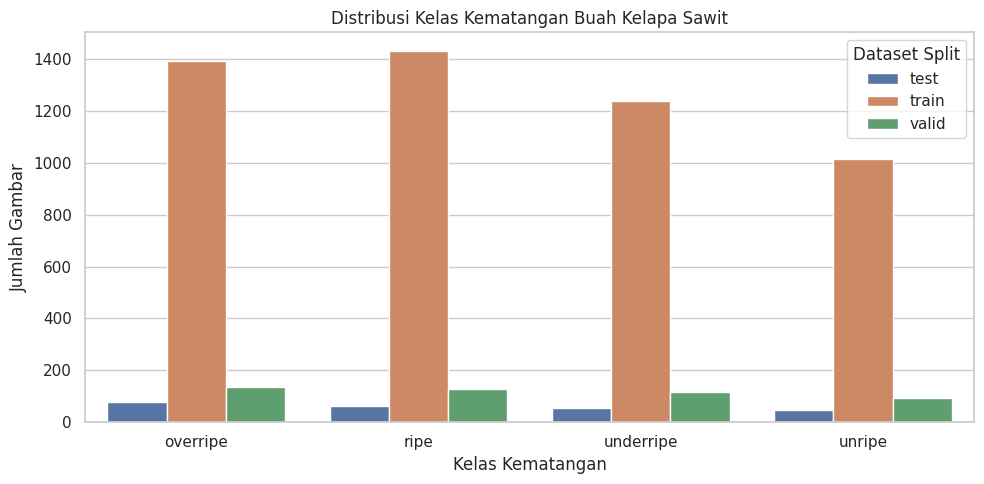

In [ ]:
#@title Visualisasi distribusi kelas yang benar
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_distribution,
    x="label",
    y="jumlah_gambar",
    hue="split",
    order=CLASS_COLUMNS
)

plt.title("Distribusi Kelas Kematangan Buah Kelapa Sawit")
plt.xlabel("Kelas Kematangan")
plt.ylabel("Jumlah Gambar")
plt.legend(title="Dataset Split")

plt.tight_layout()
plt.show()